## 1. Persiapan dan konfigurasi

Atur `BASE_DIR`, `IMAGE_DIR`, dan `LABELS_CSV` sesuai lokasi dataset. CSV minimal memiliki kolom nama file dan label. Jika CSV tidak tersedia, notebook mencoba membaca label dari nama folder kelas.

In [1]:
from pathlib import Path
import os, json, hashlib, random, warnings, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
    ConfusionMatrixDisplay, accuracy_score, precision_recall_fscore_support, f1_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

BASE_DIR = Path(r"C:\Klasifikasi CNN")
IMAGE_DIR = BASE_DIR / "OceanicLife Dataset"
LABELS_CSV = BASE_DIR / "labels.csv"  # opsional jika label berasal dari folder
OUT_DIR = BASE_DIR / "output_final"
OUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
HEAD_EPOCHS = 15
FINE_TUNE_EPOCHS = 8
RUN_FINE_TUNING = True
FINE_TUNE_LAST_LAYERS = 30
AUTOTUNE = tf.data.AUTOTUNE

assert IMAGE_DIR.is_dir(), f"Folder gambar tidak ditemukan: {IMAGE_DIR}"
print("TensorFlow:", tf.__version__)
print("Folder gambar:", IMAGE_DIR)
print("Output:", OUT_DIR)

TensorFlow: 2.21.0
Folder gambar: C:\Klasifikasi CNN\OceanicLife Dataset
Output: C:\Klasifikasi CNN\output_final


## 2. Memuat indeks gambar dan label

Setiap gambar diindeks menggunakan path relatif agar aman jika ada nama file yang sama di subfolder berbeda. Jika memakai CSV, ubah `CSV_FILENAME_COL` dan `CSV_LABEL_COL` sesuai nama kolom sebenarnya.

In [2]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".gif"}
image_paths = [p for p in IMAGE_DIR.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
assert image_paths, "Tidak ada file gambar yang ditemukan."
image_index = pd.DataFrame({
    "relative_path": [p.relative_to(IMAGE_DIR).as_posix() for p in image_paths],
    "filename": [p.name for p in image_paths],
    "full_path": [str(p) for p in image_paths]
})

CSV_FILENAME_COL = "filename"
CSV_LABEL_COL = "label"
if LABELS_CSV.is_file():
    raw_labels = pd.read_csv(LABELS_CSV)
    assert {CSV_FILENAME_COL, CSV_LABEL_COL}.issubset(raw_labels.columns), (
        f"CSV harus memiliki kolom {CSV_FILENAME_COL!r} dan {CSV_LABEL_COL!r}. "
        f"Kolom ditemukan: {raw_labels.columns.tolist()}"
    )
    raw_labels["filename_key"] = raw_labels[CSV_FILENAME_COL].astype(str).str.strip().str.casefold()
    image_index["filename_key"] = image_index["filename"].str.casefold()
    # Nama file harus unik agar pemetaan CSV tidak ambigu. Gunakan relative_path di CSV bila tidak unik.
    duplicate_names = image_index[image_index.filename_key.duplicated(False)]
    assert duplicate_names.empty, (
        "Ada basename file yang sama di beberapa folder. Ubah CSV agar menggunakan relative_path "
        "dan sesuaikan pemetaan sebelum melanjutkan."
    )
    data = image_index.merge(
        raw_labels[["filename_key", CSV_LABEL_COL]], on="filename_key", how="inner", validate="one_to_one"
    ).rename(columns={CSV_LABEL_COL: "label"})
    unmatched_labels = set(raw_labels.filename_key) - set(image_index.filename_key)
    unmatched_images = set(image_index.filename_key) - set(raw_labels.filename_key)
    print("Baris label tanpa file:", len(unmatched_labels))
    print("Gambar tanpa label:", len(unmatched_images))
else:
    # Fallback: nama folder induk dipakai sebagai label kelas.
    data = image_index.copy()
    data["label"] = [Path(p).parent.name for p in data.relative_path]
    data = data[data.label.ne("")].copy()

data = data[["relative_path", "filename", "full_path", "label"]].copy()
data["label"] = data.label.astype(str).str.strip()
data = data[data.label.ne("")].reset_index(drop=True)
assert len(data) > 0 and data.label.nunique() >= 2, "Data/label tidak cukup untuk klasifikasi."
print("Jumlah gambar berlabel:", len(data))
print("Jumlah kelas:", data.label.nunique())
display(data.head())

Baris label tanpa file: 0
Gambar tanpa label: 1
Jumlah gambar berlabel: 7990
Jumlah kelas: 8


,relative_path,filename,full_path,label
0,001v5h0d.jpg,001v5h0d.jpg,C:\Klasifikasi CNN\OceanicLife Dataset\001v5h0...,Other marine organisms
1,002ojjl6.jpg,002ojjl6.jpg,C:\Klasifikasi CNN\OceanicLife Dataset\002ojjl...,Seaweed
2,00dx9zud.JPG,00dx9zud.JPG,C:\Klasifikasi CNN\OceanicLife Dataset\00dx9zu...,Other marine organisms
3,00gohyw5.jpg,00gohyw5.jpg,C:\Klasifikasi CNN\OceanicLife Dataset\00gohyw...,Fish
4,00lvn4tu.gif,00lvn4tu.gif,C:\Klasifikasi CNN\OceanicLife Dataset\00lvn4t...,Other marine organisms


## 3. Validasi file dan audit kualitas gambar

Gambar yang tidak dapat dibuka tidak boleh diam-diam masuk ke training. Notebook mencatat file rusak/hilang. Perbaikan file hanya dilakukan jika gambar masih dapat dibaca secara utuh; gambar yang tidak dapat dipulihkan dikeluarkan dengan alasan terdokumentasi.

c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\PIL\Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Gambar valid: 7983
Gambar tidak valid: 7


,relative_path,label,error
2307,aiuy0d4p.jpg,Other marine organisms,image file is truncated (13 bytes not processed)
2316,ajldgtd3.jpg,Other marine organisms,image file is truncated (13 bytes not processed)
2509,bfhn5ax2.jpg,Other marine organisms,image file is truncated (13 bytes not processed)
4395,jz37ml67.jpg,Other marine organisms,image file is truncated (13 bytes not processed)
4751,llcyuiir.jpg,Other marine organisms,image file is truncated (13 bytes not processed)
6817,upyvd3qx.jpg,Other marine organisms,image file is truncated (13 bytes not processed)
6866,uxjl82go.jpg,Other marine organisms,image file is truncated (13 bytes not processed)


,format,mode,jumlah
0,GIF,P,30
1,JPEG,L,9
2,JPEG,RGB,7705
3,MPO,RGB,10
4,PNG,P,39
5,PNG,RGB,89
6,PNG,RGBA,58
7,WEBP,RGB,43


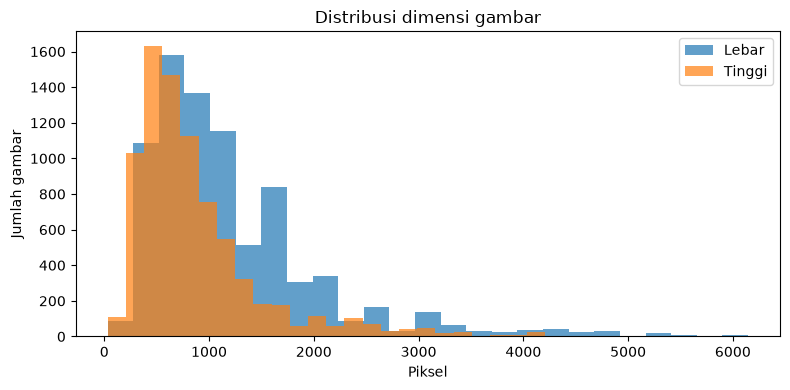

In [3]:
def inspect_image(path):
    try:
        with Image.open(path) as im:
            fmt, size, mode = im.format, im.size, im.mode
            im.convert("RGB").load()
        return {"valid": True, "format": fmt, "width": size[0], "height": size[1], "mode": mode, "error": ""}
    except Exception as exc:
        return {"valid": False, "format": None, "width": None, "height": None, "mode": None, "error": str(exc)[:250]}

image_checks = pd.DataFrame([inspect_image(p) for p in data.full_path])
data = pd.concat([data.reset_index(drop=True), image_checks], axis=1)
invalid_images = data.loc[~data.valid, ["relative_path", "label", "error"]].copy()
invalid_images.to_csv(OUT_DIR / "invalid_images.csv", index=False)
print("Gambar valid:", int(data.valid.sum()))
print("Gambar tidak valid:", len(invalid_images))
display(invalid_images.head(20))
data = data.loc[data.valid].drop(columns=["valid", "error"]).reset_index(drop=True)
assert data.label.nunique() >= 2, "Kelas tersisa kurang dari dua setelah validasi gambar."

# Ringkasan karakteristik citra
image_profile = data.groupby(["format", "mode"], dropna=False).size().rename("jumlah").reset_index()
display(image_profile)
fig, ax = plt.subplots(figsize=(8,4))
ax.hist(data.width.dropna(), bins=25, alpha=.7, label="Lebar")
ax.hist(data.height.dropna(), bins=25, alpha=.7, label="Tinggi")
ax.set(title="Distribusi dimensi gambar", xlabel="Piksel", ylabel="Jumlah gambar"); ax.legend(); plt.tight_layout(); plt.show()

## 4. Audit duplikasi identik sebelum pembagian data

Hash SHA-256 mendeteksi file yang identik byte-per-byte. Duplikat identik dengan label sama disimpan satu kali. Jika gambar identik memiliki label berbeda, proses dihentikan karena perlu keputusan audit manusia. Hash tidak mendeteksi semua near-duplicate (misalnya gambar sama yang di-resize atau dikompresi ulang); pemeriksaan visual tetap diperlukan.

In [4]:
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""): h.update(chunk)
    return h.hexdigest()
data["sha256"] = data.full_path.map(sha256_file)
conflicting_hashes = data.groupby("sha256").label.nunique()
conflicting_hashes = conflicting_hashes[conflicting_hashes > 1]
assert conflicting_hashes.empty, (
    "Konten gambar identik memiliki label berbeda. Periksa file berikut sebelum split: "
    + str(conflicting_hashes.index.tolist()[:20])
)
duplicate_rows = data[data.duplicated("sha256", keep="first")].copy()
duplicate_rows.to_csv(OUT_DIR / "exact_duplicates_removed.csv", index=False)
data = data.drop_duplicates("sha256", keep="first").reset_index(drop=True)
print("Duplikasi identik dikeluarkan:", len(duplicate_rows))
print("Data unik tersisa:", len(data))

# Simpan inventaris audit manual. Edit kolom audit_status, corrected_label, dan notes.
audit_inventory = data[["relative_path", "filename", "label", "sha256"]].copy()
audit_inventory["audit_status"] = "pending"  # confirmed / corrected / exclude
audit_inventory["corrected_label"] = ""
audit_inventory["notes"] = ""
audit_path = OUT_DIR / "audit_inventory.csv"
if not audit_path.exists(): audit_inventory.to_csv(audit_path, index=False)
print("Inventaris audit:", audit_path)
print("Sebelum training, tinjau label dan gambar. Isi audit_status: confirmed, corrected, atau exclude.")

Duplikasi identik dikeluarkan: 6956
Data unik tersisa: 1027
Inventaris audit: C:\Klasifikasi CNN\output_final\audit_inventory.csv
Sebelum training, tinjau label dan gambar. Isi audit_status: confirmed, corrected, atau exclude.


In [ ]:
# AUDIT TAMBAHAN: ANALISIS KELOMPOK DUPLIKASI

# Menggabungkan data unik dan baris duplikat
all_hash_rows = pd.concat(
    [data, duplicate_rows],
    ignore_index=True
)

# Menghitung jumlah salinan setiap hash
hash_counts = all_hash_rows.groupby("sha256").size()

print("Jumlah gambar sebelum deduplikasi:", len(all_hash_rows))
print("Jumlah gambar unik:", hash_counts.size)
print("Jumlah baris duplikat yang dihapus:", len(duplicate_rows))
print("Jumlah kelompok yang memiliki duplikasi:", (hash_counts > 1).sum())
print("Jumlah salinan terbanyak dalam satu kelompok:", hash_counts.max())

# Distribusi kelas sebelum dan sesudah deduplikasi
before = all_hash_rows.groupby("label").size()
after = data.groupby("label").size()

comparison = pd.DataFrame({
    "Sebelum deduplikasi": before,
    "Sesudah deduplikasi": after
}).fillna(0).astype(int)

comparison["Jumlah dihapus"] = (
    comparison["Sebelum deduplikasi"]
    - comparison["Sesudah deduplikasi"]
)

comparison["Persentase tersisa"] = (
    comparison["Sesudah deduplikasi"]
    / comparison["Sebelum deduplikasi"] * 100
).round(2)

display(comparison)

# Melihat 10 kelompok duplikasi terbesar
largest_groups = (
    all_hash_rows.groupby("sha256")
    .agg(
        jumlah_salinan=("filename", "count"),
        label=("label", "first"),
        contoh_file=("filename", "first")
    )
    .sort_values("jumlah_salinan", ascending=False)
    .head(10)
)

display(largest_groups)

Jumlah gambar sebelum deduplikasi: 7983
Jumlah gambar unik: 1027
Jumlah baris duplikat yang dihapus: 6956
Jumlah kelompok yang memiliki duplikasi: 970
Jumlah salinan terbanyak dalam satu kelompok: 13


,Sebelum deduplikasi,Sesudah deduplikasi,Jumlah dihapus,Persentase tersisa
label,,,,
Coral,511,66,445,12.92
Crustaceans,556,77,479,13.85
Fish,1511,189,1322,12.51
Octopuses,356,42,314,11.80
Other marine organisms,3953,516,3437,13.05
Seaweed,64,10,54,15.62
Shark,699,83,616,11.87
Sponges,333,44,289,13.21


,jumlah_salinan,label,contoh_file
sha256,,,
66b1ecd9ec3ccd6b24b7664fc9527a239b1528d78e145fc8111dc5ee547803cd,13,Other marine organisms,39eknqqi.jpg
0a5ad381a71c7f889242d94a38e61a86a9c9c8527296dec9bea736e926991887,12,Other marine organisms,02tr376x.jpg
0436a46487fda57a5418fafcbc72714f1cd7ac88141b663fda553f9582c29316,12,Other marine organisms,8p0fy5b5.jpg
76234b46da3e00e27af74118bcc7d5332e1af5c8eae3a59546643cbef5b9c993,12,Other marine organisms,40vro2bz.jpg
7b9ef9689d94487ee99b1ecc9f5dc98ba3a2744127de46ecc4a1b6c12c731753,12,Other marine organisms,1t7xfo8i.jpg
78ddd5c972c10d45e769292b27aa914b1ece1fb0bc7b1d0473b0cb06aac5b1f2,12,Octopuses,0iyzo2a1.jpg
0f4a617e0072bde5096217efee750ef334578a47890d93731d28610968f43324,12,Other marine organisms,6p11y3vl.JPG
61f5ae720c8e4b218ff3f6b1c7ea733b91db77066363cc3fbbd35abce4a60c40,12,Shark,2dm4k34s.jpg
63ddc317027f9e0360f8a4271c6fe3b404ff4279ca54e7fd4173194892e1d185,12,Fish,08k6qtny.jpg


In [61]:
from pathlib import Path
import pandas as pd

# Lokasi utama proyek
BASE_DIR = Path(r"C:\Klasifikasi CNN")

# Lokasi file master dan output
MASTER_PATH = BASE_DIR / "Master_Rekapitulasi_Dataset_Marine_Organisms.xlsx"
OUT_DIR = BASE_DIR / "output_final"
AUDIT_PATH = OUT_DIR / "audit_inventory.csv"

print("=== PEMERIKSAAN FOLDER PROYEK ===")
print("BASE_DIR:", BASE_DIR)
print("BASE_DIR ditemukan:", BASE_DIR.exists())

# Tampilkan isi folder utama
if BASE_DIR.exists():
    print("\nIsi folder C:\\Klasifikasi CNN:")
    for item in BASE_DIR.iterdir():
        print("-", item.name)

print("\n=== PEMERIKSAAN FILE ===")
print("Master Excel:", MASTER_PATH.exists())
print("Audit inventory:", AUDIT_PATH.exists())
print("Folder output:", OUT_DIR.exists())

assert MASTER_PATH.exists(), "Master Excel tidak ditemukan."
assert AUDIT_PATH.exists(), "Audit inventory tidak ditemukan."

# Baca inventaris audit
audit_check = pd.read_csv(AUDIT_PATH).fillna("")

print("\nJumlah gambar:", len(audit_check))
print("Jumlah kelas:", audit_check["label"].nunique())

display(
    audit_check.groupby("label")
    .size()
    .rename("jumlah_gambar")
    .reset_index()
)

print("\nStatus audit:")
display(audit_check["audit_status"].value_counts())

=== PEMERIKSAAN FOLDER PROYEK ===
BASE_DIR: C:\Klasifikasi CNN
BASE_DIR ditemukan: True

Isi folder C:\Klasifikasi CNN:
- 30 gambar dengan confiden terendah.png
- app.py
- distribusi gambar per kelas.png
- distribusi lebar dan tinggi gmbar.png
- Eksperimen_MobileNetV2_Audit_Finetuning_Balancing.ipynb
- Explorasi data.png
- hasil_eksperimen
- KlasifikasiCNN_GABUNGAN_AUDIT_LABEL_FIXED.ipynb
- KlasifikasiCNN_GABUNGAN_REKOMENDASI.ipynb
- labels.csv
- labels_unique.csv
- Lizza_Putri_Sugiarto_Test2_KlasifikasiCNN.ipynb
- Lizza_Putri_Sugiarto_Test2_KlasifikasiCNN_RAPI.ipynb
- Lizza_Putri_Sugiarto_Test2_KlasifikasiCNN_REVISI.ipynb
- Master_Rekapitulasi_Dataset_Marine_Organisms.xlsx
- MobileNetV2_Revisi_Lanjutan_Audit_MacroF1.ipynb
- OceanicLife Dataset
- Oceanic_Life_CNN_Notebook_Final.ipynb
- output
- output_final
- pemeriksaan gambar acak.png
- requirements.txt
- test.csv
- train.csv
- validation.csv
- visual label audit.png
- visualisasi contoh gambar.png

=== PEMERIKSAAN FILE ===
Master Ex

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12268\2050230968.py:31: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  audit_check = pd.read_csv(AUDIT_PATH).fillna("")


,label,jumlah_gambar
0,Coral,66
1,Crustaceans,77
2,Fish,189
3,Octopuses,42
4,Other marine organisms,516
5,Seaweed,10
6,Shark,83
7,Sponges,44



Status audit:


audit_status
pending    1027
Name: count, dtype: int64

In [63]:
# VERIFIKASI LOKASI DATASET ASLI

IMAGE_DIR = BASE_DIR / "OceanicLife Dataset"

print("Lokasi dataset:", IMAGE_DIR)
print("Folder ditemukan:", IMAGE_DIR.exists())

if IMAGE_DIR.exists():

    image_files = [
        p for p in IMAGE_DIR.rglob("*")
        if p.is_file()
    ]

    print("Total file dalam folder:", len(image_files))

    print("\nContoh file:")
    for p in image_files[:10]:
        print(p.relative_to(IMAGE_DIR))

else:
    print("Folder dataset tidak ditemukan.")

Lokasi dataset: C:\Klasifikasi CNN\OceanicLife Dataset
Folder ditemukan: True
Total file dalam folder: 7991

Contoh file:
001v5h0d.jpg
002ojjl6.jpg
00dx9zud.JPG
00gohyw5.jpg
00lvn4tu.gif
015e0ase.jpg
015us06k.jpg
017s6334.jpeg
01cqbman.jpg
01fifu6i.jpg


In [65]:
# VALIDASI KESESUAIAN INVENTARIS DAN FILE ASLI

from pathlib import Path
import pandas as pd

# Ambil seluruh file dari folder dataset
all_files = {
    p.name.lower(): str(p)
    for p in IMAGE_DIR.rglob("*")
    if p.is_file()
}

# Ambil nama file dari audit inventory
inventory = pd.read_csv(AUDIT_PATH)

inventory_names = set(
    inventory["relative_path"].astype(str).str.lower()
)

disk_names = set(all_files.keys())

# Perbandingan
matched = inventory_names & disk_names
missing = inventory_names - disk_names
not_in_inventory = disk_names - inventory_names

print("=== HASIL PENCOCOKAN INVENTARIS ===")
print("Total inventaris:", len(inventory_names))
print("File ditemukan:", len(matched))
print("File tidak ditemukan:", len(missing))
print("File belum masuk inventaris:", len(not_in_inventory))

# Tampilkan file yang tidak ditemukan
if missing:
    print("\nFile inventaris yang tidak ditemukan:")
    display(pd.DataFrame({"filename": sorted(missing)}))

# Tampilkan ringkasan file di luar inventaris
print("\nContoh file yang belum masuk inventaris:")
display(
    pd.DataFrame({
        "filename": sorted(not_in_inventory)[:20]
    })
)

# Simpan laporan pencocokan
matching_report = pd.DataFrame({
    "filename": sorted(inventory_names),
    "file_exists": [
        name in disk_names for name in sorted(inventory_names)
    ]
})

matching_report.to_csv(
    OUT_DIR / "inventory_matching_report.csv",
    index=False
)

print("\nLaporan disimpan di:")
print(OUT_DIR / "inventory_matching_report.csv")

=== HASIL PENCOCOKAN INVENTARIS ===
Total inventaris: 1027
File ditemukan: 1027
File tidak ditemukan: 0
File belum masuk inventaris: 6964

Contoh file yang belum masuk inventaris:


,filename
0,0olckdkz.jpg
1,0we3o4ny.jpg
2,1380gmdl.jpg
3,14c1sh7x.jpg
4,1530tj1g.jpg
5,15oooy28.jpg
6,161x0u48.jpg
7,167j0ycq.jpg
8,187n00nf.jpg
9,197qlsrf.jpg



Laporan disimpan di:
C:\Klasifikasi CNN\output_final\inventory_matching_report.csv


In [ ]:
# MEMBUAT PEMETAAN AUDIT OTHER MARINE ORGANISMS

import pandas as pd

# Baca inventaris asli
inventory = pd.read_csv(AUDIT_PATH)

# Ambil kategori Other marine organisms
other_data = inventory[
    inventory["label"].str.strip() == "Other marine organisms"
].copy().reset_index(drop=True)

# Buat nomor sesuai urutan fungsi tampilkan_audit()
other_data.insert(
    0, "visual_index",
    range(1, len(other_data) + 1)
)

# Tambahkan informasi halaman audit
other_data["audit_page"] = (
    (other_data["visual_index"] - 1) // 24 + 1
)

# Siapkan kolom keputusan audit
other_data["object_identification"] = ""
other_data["final_audit_status"] = "pending"
other_data["corrected_label"] = ""
other_data["audit_notes"] = ""

# Simpan hasil pemetaan
mapping_path = OUT_DIR / "OtherMarine_Audit_Mapping.csv"

other_data.to_csv(mapping_path, index=False)

print("=== PEMETAAN AUDIT SELESAI ===")
print("Total gambar:", len(other_data))
print("Jumlah halaman:", other_data["audit_page"].nunique())
print("File pemetaan:", mapping_path)

display(
    other_data[
        ["visual_index", "filename", "label", "audit_page"]
    ].head(15)
)

# Pastikan jumlahnya sesuai
assert len(other_data) == 516
assert other_data["filename"].is_unique

print("\nValidasi pemetaan berhasil.")


=== PEMETAAN AUDIT SELESAI ===
Total gambar: 516
Jumlah halaman: 22
File pemetaan: C:\Klasifikasi CNN\output_final\OtherMarine_Audit_Mapping.csv


,visual_index,filename,label,audit_page
0,1,001v5h0d.jpg,Other marine organisms,1
1,2,00dx9zud.JPG,Other marine organisms,1
2,3,00lvn4tu.gif,Other marine organisms,1
3,4,015us06k.jpg,Other marine organisms,1
4,5,01cqbman.jpg,Other marine organisms,1
5,6,01ji8io2.jpg,Other marine organisms,1
6,7,01n1y044.jpg,Other marine organisms,1
7,8,02tr376x.jpg,Other marine organisms,1
8,9,03hrvmyq.jpg,Other marine organisms,1
9,10,04bcs2eh.jpg,Other marine organisms,1



Validasi pemetaan berhasil.


In [67]:
# VALIDASI URUTAN GAMBAR DENGAN DATA ASLI

# Ambil data sesuai kategori Other marine organisms
visual_data = (
    data[data["label"].str.strip() == "Other marine organisms"]
    .reset_index(drop=True)
)

# Bandingkan urutan filename
mapping_names = (
    other_data["filename"].astype(str).str.lower().tolist()
)

visual_names = (
    visual_data["filename"].astype(str).str.lower().tolist()
)

print("=== VALIDASI URUTAN GAMBAR ===")
print("Jumlah data visual:", len(visual_names))
print("Jumlah data mapping:", len(mapping_names))

order_match = mapping_names == visual_names

print("Urutan gambar cocok:", order_match)

if not order_match:
    differences = [
        {
            "nomor_visual": i + 1,
            "mapping": mapping_names[i],
            "data_visual": visual_names[i]
        }
        for i in range(min(len(mapping_names), len(visual_names)))
        if mapping_names[i] != visual_names[i]
    ]

    display(pd.DataFrame(differences).head(20))

    raise ValueError(
        "Urutan gambar berbeda. Jangan terapkan keputusan audit dahulu."
    )

# Periksa batas halaman
print("\n=== PEMERIKSAAN BATAS HALAMAN ===")

for idx in [1, 24, 25, 48, 49, 72, 73, 480, 481, 516]:
    row = other_data.iloc[idx - 1]
    print(
        f"Nomor {idx:3} | "
        f"Halaman {row.audit_page:2} | "
        f"{row.filename}"
    )

print("\nVALIDASI URUTAN BERHASIL")

=== VALIDASI URUTAN GAMBAR ===
Jumlah data visual: 516
Jumlah data mapping: 516
Urutan gambar cocok: True

=== PEMERIKSAAN BATAS HALAMAN ===
Nomor   1 | Halaman  1 | 001v5h0d.jpg
Nomor  24 | Halaman  1 | 0ave39n4.jpg
Nomor  25 | Halaman  2 | 0b9wozxe.jpg
Nomor  48 | Halaman  2 | 0i5l1el6.jpg
Nomor  49 | Halaman  3 | 0ikawvcf.jpg
Nomor  72 | Halaman  3 | 0pj528nm.jpg
Nomor  73 | Halaman  4 | 0pjzcrjg.jpg
Nomor 480 | Halaman 20 | gcujd317.jpg
Nomor 481 | Halaman 21 | ghq3ij9e.jpg
Nomor 516 | Halaman 22 | xkl6xoso.jpg

VALIDASI URUTAN BERHASIL


In [68]:
# MENYIAPKAN MASTER AUDIT 516 GAMBAR

master_audit = other_data.copy()

# Pastikan seluruh kolom audit tersedia
master_audit["object_identification"] = ""
master_audit["final_audit_status"] = "pending"
master_audit["corrected_label"] = ""
master_audit["audit_notes"] = ""

# Simpan master audit awal
MASTER_AUDIT_PATH = OUT_DIR / "OtherMarine_Master_Audit.csv"

master_audit.to_csv(
    MASTER_AUDIT_PATH,
    index=False
)

print("=== MASTER AUDIT BERHASIL DISIAPKAN ===")
print("Total gambar:", len(master_audit))
print("Status awal:", master_audit["final_audit_status"].value_counts().to_dict())
print("Lokasi:", MASTER_AUDIT_PATH)

display(
    master_audit[
        [
            "visual_index",
            "filename",
            "label",
            "final_audit_status",
            "corrected_label"
        ]
    ].head(10)
)

assert len(master_audit) == 516
assert master_audit["filename"].is_unique
assert master_audit["final_audit_status"].eq("pending").all()

print("\nVALIDASI MASTER AUDIT BERHASIL")

=== MASTER AUDIT BERHASIL DISIAPKAN ===
Total gambar: 516
Status awal: {'pending': 516}
Lokasi: C:\Klasifikasi CNN\output_final\OtherMarine_Master_Audit.csv


,visual_index,filename,label,final_audit_status,corrected_label
0,1,001v5h0d.jpg,Other marine organisms,pending,
1,2,00dx9zud.JPG,Other marine organisms,pending,
2,3,00lvn4tu.gif,Other marine organisms,pending,
3,4,015us06k.jpg,Other marine organisms,pending,
4,5,01cqbman.jpg,Other marine organisms,pending,
5,6,01ji8io2.jpg,Other marine organisms,pending,
6,7,01n1y044.jpg,Other marine organisms,pending,
7,8,02tr376x.jpg,Other marine organisms,pending,
8,9,03hrvmyq.jpg,Other marine organisms,pending,
9,10,04bcs2eh.jpg,Other marine organisms,pending,



VALIDASI MASTER AUDIT BERHASIL


## 5. Pemeriksaan visual dan penerapan keputusan audit label

Buka `output_final/audit_inventory.csv` menggunakan Excel/Google Sheets. Untuk setiap baris, isi `audit_status` dengan `confirmed`, `corrected`, atau `exclude`. Jika `corrected`, isi `corrected_label` menggunakan nama kelas yang valid dan tulis alasan pada `notes`. Jika `exclude`, tulis alasan pengeluaran. Simpan CSV, lalu jalankan ulang notebook dari awal. Training sengaja dihentikan jika masih ada status `pending`.

In [12]:
from PIL import Image
import matplotlib.pyplot as plt
import math

def tampilkan_audit(kelas, halaman=1, per_halaman=24):

    subset = data[data["label"] == kelas].reset_index(drop=True)

    start = (halaman - 1) * per_halaman
    end = min(start + per_halaman, len(subset))

    sample = subset.iloc[start:end]

    cols = 4
    rows = math.ceil(len(sample) / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(16, rows * 3)
    )

    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    for ax in axes:
        ax.axis("off")

    for i, row in enumerate(sample.itertuples()):
        try:
            with Image.open(row.full_path) as img:
                axes[i].imshow(img.convert("RGB"))

            axes[i].set_title(
                f"{i + start + 1}. {row.filename}\nLabel: {row.label}",
                fontsize=8
            )
        except Exception as e:
            axes[i].set_title(f"Error: {row.filename}\n{e}")

    plt.suptitle(
        f"AUDIT: {kelas} | {start+1}–{end} dari {len(subset)} gambar",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

    print(f"Total gambar kelas {kelas}: {len(subset)}")
    print(f"Halaman {halaman}")


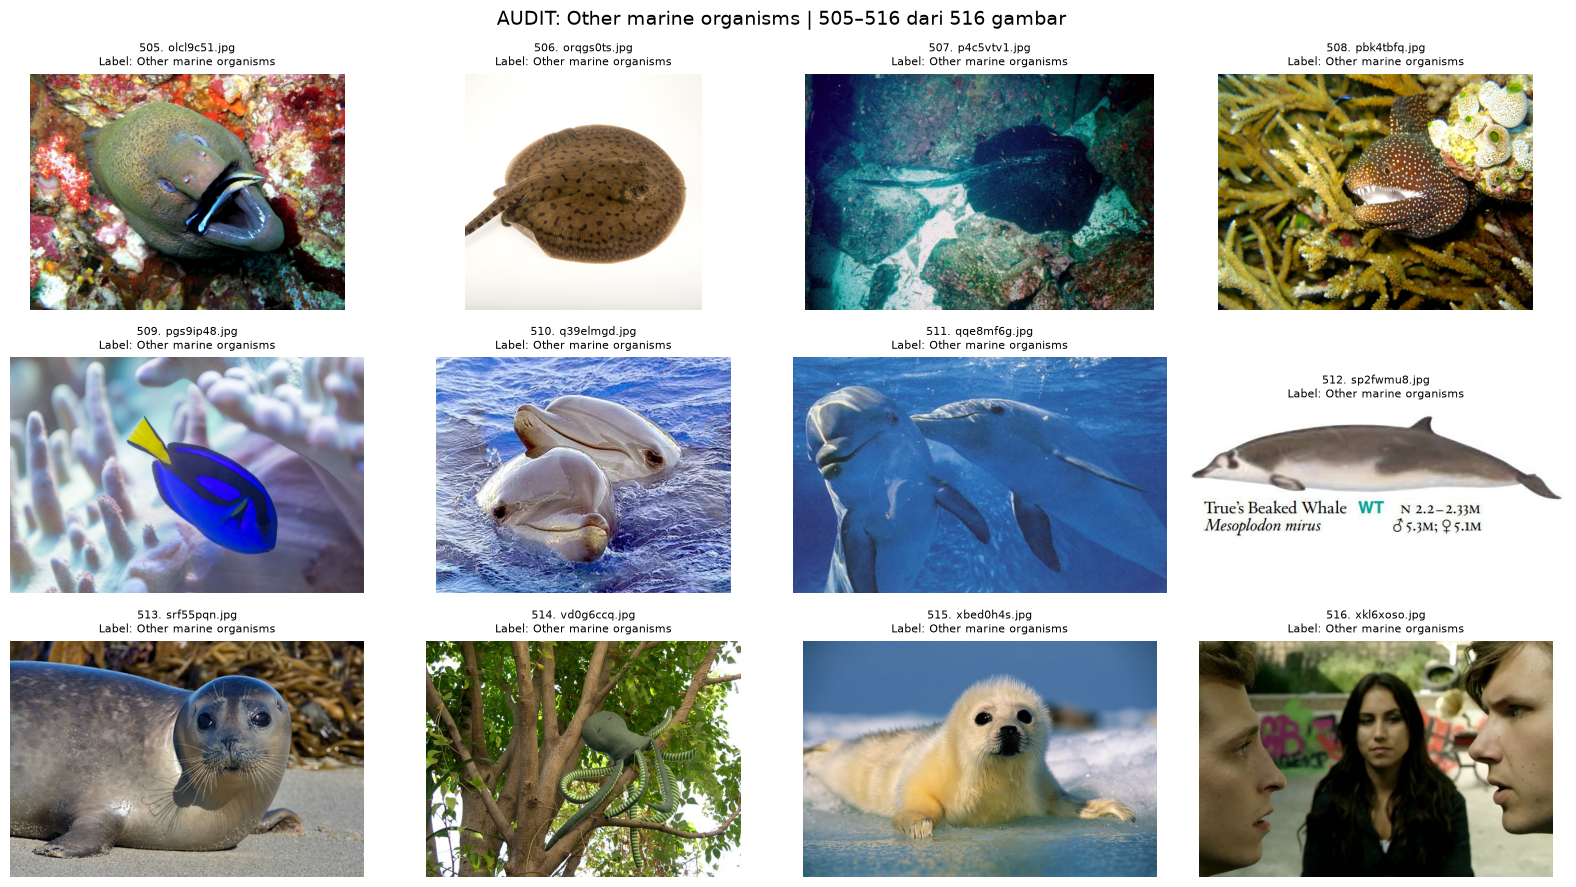

Total gambar kelas Other marine organisms: 516
Halaman 22


In [58]:
# PENGATURAN AUDIT GAMBAR

KELAS_AUDIT = "Other marine organisms"
HALAMAN_AUDIT = 22

tampilkan_audit(
    KELAS_AUDIT,
    halaman=HALAMAN_AUDIT,
    per_halaman=24
)


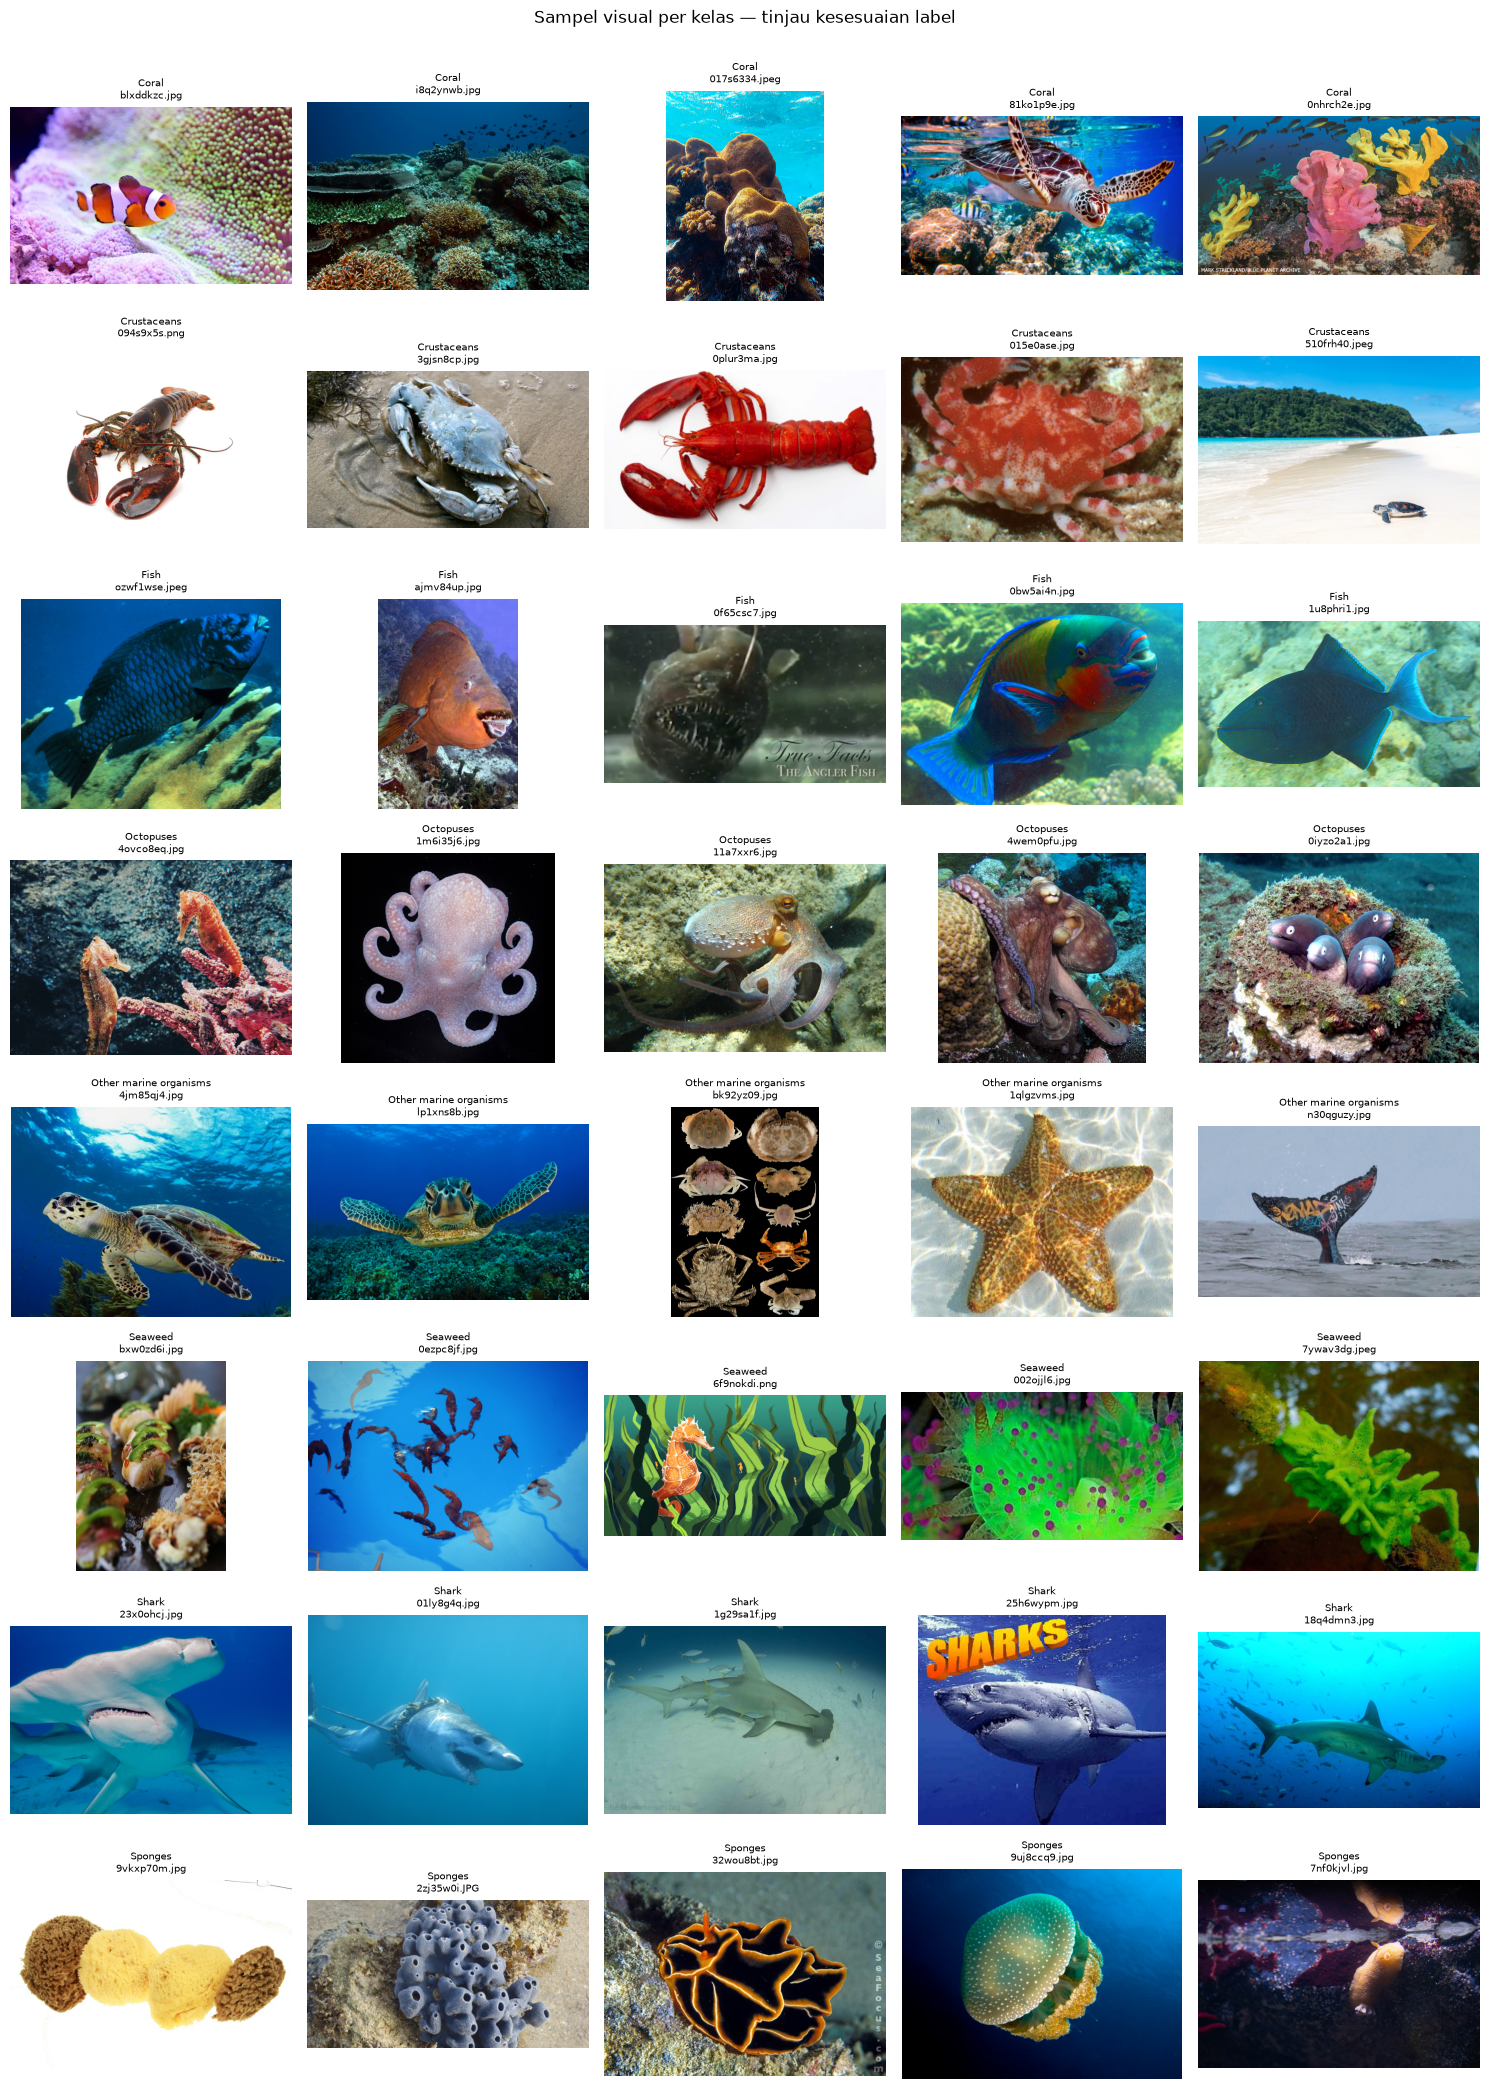

In [14]:
# PREVIEW SAMPEL GAMBAR PER KELAS

N_PREVIEW_PER_CLASS = 5
classes_preview = sorted(data.label.unique())

fig, axes = plt.subplots(
    len(classes_preview),
    N_PREVIEW_PER_CLASS,
    figsize=(15, max(3, 2.6 * len(classes_preview)))
)

axes = np.array(axes).reshape(
    len(classes_preview),
    N_PREVIEW_PER_CLASS
)

for r, cls in enumerate(classes_preview):
    sample = data[data.label == cls].sample(
        n=min(N_PREVIEW_PER_CLASS, (data.label == cls).sum()),
        random_state=SEED
    )

    for col in range(N_PREVIEW_PER_CLASS):
        ax = axes[r, col]
        ax.axis("off")

        if col < len(sample):
            row = sample.iloc[col]

            with Image.open(row.full_path) as im:
                ax.imshow(im.convert("RGB"))

            ax.set_title(
                f"{cls}\n{row.filename}",
                fontsize=7
            )

plt.suptitle(
    "Sampel visual per kelas — tinjau kesesuaian label",
    y=1.002
)
plt.tight_layout()
plt.show()


In [ ]:
# MUAT DAN TERAPKAN KEPUTUSAN AUDIT MANUAL

assert audit_path.exists(), "File audit_inventory.csv belum dibuat."

audit = pd.read_csv(audit_path).fillna("")

required_audit = {
    "relative_path",
    "audit_status",
    "corrected_label",
    "notes"
}

assert required_audit.issubset(audit.columns), (
    f"Kolom audit wajib: {required_audit}"
)

assert not audit.relative_path.duplicated().any(), (
    "Ada path duplikat di audit inventory."
)

assert set(audit.relative_path) == set(data.relative_path), (
    "Inventaris audit tidak cocok dengan data saat ini."
)

allowed_status = {"confirmed", "corrected", "exclude"}

unknown_status = set(audit.audit_status.str.strip()) - allowed_status

assert not unknown_status, (
    f"Audit belum lengkap atau status tidak valid: {unknown_status}"
)

assert audit.audit_status.ne("pending").all(), (
    "Masih ada gambar berstatus pending. Selesaikan audit dahulu."
)

corrections = audit[audit.audit_status.eq("corrected")]

valid_classes = set(data.label.unique())

assert corrections.corrected_label.astype(str).str.strip().ne("").all(), (
    "Baris corrected harus memiliki corrected_label."
)

invalid_corrected = (
    set(corrections.corrected_label.astype(str).str.strip())
    - valid_classes
)

assert not invalid_corrected, (
    f"Label koreksi bukan kelas yang dikenal: {invalid_corrected}"
)

data = data.merge(
    audit[[
        "relative_path",
        "audit_status",
        "corrected_label",
        "notes"
    ]],
    on="relative_path",
    validate="one_to_one"
)

data.loc[data.audit_status.eq("corrected"), "label"] = (
    data.loc[data.audit_status.eq("corrected"), "corrected_label"]
    .astype(str)
    .str.strip()
)

excluded = data[data.audit_status.eq("exclude")].copy()

excluded.to_csv(
    OUT_DIR / "excluded_by_manual_audit.csv",
    index=False
)

data = data[data.audit_status.ne("exclude")].copy().reset_index(drop=True)

assert data.label.nunique() >= 2, (
    "Jumlah kelas tidak cukup setelah audit."
)

print(
    "Label dikoreksi:", len(corrections),
    "| Gambar dikeluarkan:", len(excluded)
)

display(
    data.groupby("label")
    .size()
    .rename("jumlah")
    .reset_index()
)

data.to_csv(
    OUT_DIR / "dataset_after_audit.csv",
    index=False
)


## 6. EDA setelah audit

Distribusi kelas dihitung setelah gambar tidak valid, duplikasi identik, dan keputusan audit diterapkan. Ketidakseimbangan kelas akan ditangani pada training melalui class weighting, bukan dengan mengubah validation/test.

In [ ]:
class_counts = data.label.value_counts().sort_index()
distribution = class_counts.rename_axis("kelas").reset_index(name="jumlah_gambar")
distribution["persentase"] = (distribution.jumlah_gambar / len(data) * 100).round(2)
display(distribution)
fig, ax = plt.subplots(figsize=(10,5))
ax.bar(distribution.kelas, distribution.jumlah_gambar)
ax.set(title="Distribusi kelas setelah audit", xlabel="Kelas", ylabel="Jumlah gambar")
ax.tick_params(axis="x", rotation=40); plt.tight_layout(); plt.show()
print("Rasio kelas terbesar/terkecil:", round(class_counts.max()/class_counts.min(), 2))

## 7. Pembagian data 80:10:10 dengan stratified splitting

Pembagian dilakukan setelah deduplikasi dan audit label. Tahap pertama menyisihkan 20% sebagai data sementara, kemudian membaginya sama rata menjadi validation dan test. `stratify` menjaga proporsi kelas. Setiap kelas harus memiliki minimal tiga gambar agar dapat muncul pada ketiga subset. Karena duplikasi identik telah dikelompokkan/dihapus sebelum split, gambar identik tidak tersebar ke subset berbeda.

In [ ]:
class_counts = data.label.value_counts()
rare_classes = class_counts[class_counts < 10]
assert rare_classes.empty, (
    "Stratified split 80:10:10 membutuhkan minimal 10 gambar per kelas untuk split dua tahap 80:10:10. "
    f"Kelas bermasalah: {rare_classes.to_dict()}. Tambah data atau gabungkan kelas hanya jika secara domain benar."
)
train_df, temp_df = train_test_split(
    data, test_size=0.20, random_state=SEED, stratify=data.label
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df.label
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

split_summary = pd.DataFrame({
    "subset": ["train", "validation", "test"],
    "jumlah": [len(train_df), len(val_df), len(test_df)]
})
split_summary["persentase"] = (split_summary.jumlah / len(data) * 100).round(2)
display(split_summary)

# Verifikasi tidak ada filename/hash yang tumpang tindih antar subset
for col in ["relative_path", "sha256"]:
    assert train_df[col].is_unique and val_df[col].is_unique and test_df[col].is_unique
    assert set(train_df[col]).isdisjoint(val_df[col])
    assert set(train_df[col]).isdisjoint(test_df[col])
    assert set(val_df[col]).isdisjoint(test_df[col])

# Simpan split agar dapat direproduksi tanpa membuat pembagian baru
for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    frame.to_csv(OUT_DIR / f"{name}.csv", index=False)

class_names = sorted(train_df.label.unique().tolist())
assert set(class_names) == set(val_df.label.unique()) == set(test_df.label.unique()), "Ada kelas yang tidak terwakili pada salah satu subset."
label_to_id = {name: i for i, name in enumerate(class_names)}
id_to_label = {i: name for name, i in label_to_id.items()}
NUM_CLASSES = len(class_names)
print("Kelas:", class_names)

## 8. Preprocessing sesuai MobileNetV2

Gambar diubah menjadi RGB, di-resize ke 160×160, lalu diproses dengan `preprocess_input` MobileNetV2. Fungsi tersebut mengubah skala piksel dari 0–255 menjadi sekitar −1 hingga 1. Jangan menambahkan pembagian `/255.0` lagi. Augmentasi dilakukan di dalam model sehingga hanya aktif saat training.

In [ ]:
def decode_and_preprocess(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = preprocess_input(tf.cast(image, tf.float32))
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    return image, label

def make_dataset(frame, training=False):
    paths = frame.full_path.astype(str).to_numpy()
    labels = frame.label.map(label_to_id).to_numpy(dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training: ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_and_preprocess, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

# Cek bentuk tensor dan rentang normalisasi
for batch_images, batch_labels in train_ds.take(1):
    print("Batch image:", batch_images.shape, "| Batch label:", batch_labels.shape)
    print("Rentang piksel setelah preprocess_input:", float(tf.reduce_min(batch_images)), float(tf.reduce_max(batch_images)))

## 9. Menangani ketidakseimbangan kelas

Class weight dihitung hanya dari training set. Validation dan test dibiarkan mengikuti distribusi aslinya agar evaluasi tetap merepresentasikan data yang tidak dilatih.

In [ ]:
y_train = train_df.label.map(label_to_id).to_numpy()
weights = compute_class_weight(class_weight="balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = {int(i): float(w) for i, w in enumerate(weights)}
print("Class weight:", {id_to_label[k]: round(v, 3) for k, v in class_weight.items()})

## 10. Membangun model CNN — MobileNetV2 transfer learning

Backbone MobileNetV2 menggunakan bobot ImageNet dan dibekukan pada tahap awal. Head klasifikasi terdiri dari Global Average Pooling, Dropout, dan Dense Softmax sesuai jumlah kelas. Batch Normalization tetap dalam mode inference ketika backbone dipanggil.

In [ ]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10)
], name="training_augmentation")

backbone = MobileNetV2(
    input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet"
)
backbone.trainable = False
inputs = layers.Input(shape=(*IMG_SIZE, 3), name="image")
x = augmentation(inputs)
x = backbone(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_pool")(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="class_probabilities")(x)
model = Model(inputs, outputs, name="oceanic_mobilenetv2")

def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"]
    )
compile_model(model, 1e-3)
model.summary()

## 11. Training classifier head dan pemilihan checkpoint

Model terbaik dipilih berdasarkan **validation macro-F1**, bukan test score. Callback menghitung macro-F1 setiap epoch dan menyimpan bobot terbaik. Early stopping menggunakan validation loss sebagai penghenti tambahan.

In [ ]:
class ValidationMacroF1(tf.keras.callbacks.Callback):
    def __init__(self, validation_dataset, validation_labels, checkpoint_path):
        super().__init__(); self.validation_dataset = validation_dataset
        self.validation_labels = validation_labels; self.checkpoint_path = str(checkpoint_path)
        self.best_score = -1.0; self.best_weights = None
    def on_epoch_end(self, epoch, logs=None):
        probabilities = self.model.predict(self.validation_dataset, verbose=0)
        predictions = np.argmax(probabilities, axis=1)
        score = f1_score(self.validation_labels, predictions, labels=np.arange(NUM_CLASSES), average="macro", zero_division=0)
        if logs is not None: logs["val_macro_f1"] = score
        print(f" — val_macro_f1: {score:.4f}")
        if score > self.best_score:
            self.best_score = score; self.best_weights = self.model.get_weights()
            self.model.save(self.checkpoint_path)
    def on_train_end(self, logs=None):
        if self.best_weights is not None: self.model.set_weights(self.best_weights)

val_labels = val_df.label.map(label_to_id).to_numpy()
checkpoint_path = OUT_DIR / "best_validation_macro_f1.keras"
macro_callback = ValidationMacroF1(val_ds, val_labels, checkpoint_path)
callbacks = [macro_callback, tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
             tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6)]
start_time = time.time()
history_head = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, class_weight=class_weight, callbacks=callbacks)
print("Durasi training head (menit):", round((time.time()-start_time)/60, 2))
model = tf.keras.models.load_model(checkpoint_path)
head_history = pd.DataFrame(history_head.history)
display(head_history.tail())

## 12. Fine-tuning opsional

Fine-tuning membuka sebagian layer terakhir MobileNetV2 dengan learning rate kecil. Layer BatchNormalization tetap dibekukan untuk menjaga kestabilan. Jika `RUN_FINE_TUNING=False`, notebook menggunakan model classifier head terbaik.

In [ ]:
history_finetune = None
if RUN_FINE_TUNING:
    # Muat checkpoint terbaik dari tahap classifier head sebagai titik awal fine-tuning.
    model = tf.keras.models.load_model(checkpoint_path)
    backbone = model.get_layer("mobilenetv2_1.00_160")
    backbone.trainable = True
    for layer in backbone.layers[:-FINE_TUNE_LAST_LAYERS]: layer.trainable = False
    for layer in backbone.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization): layer.trainable = False
    compile_model(model, 1e-5)
    fine_checkpoint = OUT_DIR / "best_finetuned_validation_macro_f1.keras"
    fine_callback = ValidationMacroF1(val_ds, val_labels, fine_checkpoint)
    history_finetune = model.fit(
        train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS, class_weight=class_weight,
        callbacks=[fine_callback, tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]
    )
    model = tf.keras.models.load_model(fine_checkpoint)
    selected_checkpoint = fine_checkpoint
else:
    model = tf.keras.models.load_model(checkpoint_path)
    selected_checkpoint = checkpoint_path
print("Checkpoint terpilih:", selected_checkpoint)

## 13. Grafik proses training

Grafik berikut membantu menilai konvergensi dan indikasi overfitting. Jika fine-tuning dijalankan, riwayat kedua tahap ditampilkan terpisah agar perubahan fase training jelas.

In [ ]:
def plot_history(history_obj, title_prefix):
    hist = history_obj.history
    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    axes[0].plot(hist.get("accuracy", []), label="Training")
    axes[0].plot(hist.get("val_accuracy", []), label="Validation")
    axes[0].set(title=f"{title_prefix} — Accuracy", xlabel="Epoch", ylabel="Accuracy"); axes[0].legend(); axes[0].grid(alpha=.2)
    axes[1].plot(hist.get("loss", []), label="Training")
    axes[1].plot(hist.get("val_loss", []), label="Validation")
    axes[1].set(title=f"{title_prefix} — Loss", xlabel="Epoch", ylabel="Loss"); axes[1].legend(); axes[1].grid(alpha=.2)
    plt.tight_layout(); plt.show()
plot_history(history_head, "Classifier head")
if history_finetune is not None: plot_history(history_finetune, "Fine-tuning")

## 14. Evaluasi akhir pada test set — satu kali

Setelah konfigurasi dan checkpoint dikunci berdasarkan validation, test set digunakan untuk satu evaluasi final. Jangan memilih ulang epoch, arsitektur, threshold, atau hyperparameter berdasarkan hasil test.

In [ ]:
# Evaluasi final test set
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
y_test = test_df.label.map(label_to_id).to_numpy()
test_probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(test_probabilities, axis=1)

report = classification_report(y_test, y_pred, labels=np.arange(NUM_CLASSES), target_names=class_names, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)
metrics = {"test_loss": float(test_loss), "accuracy": float(accuracy_score(y_test,y_pred)),
    "macro_precision": float(macro_p), "macro_recall": float(macro_r), "macro_f1": float(macro_f1),
    "weighted_precision": float(weighted_p), "weighted_recall": float(weighted_r), "weighted_f1": float(weighted_f1),
    "test_samples": int(len(y_test)), "selected_checkpoint": selected_checkpoint.name}
print("Metrik test final:"); display(pd.DataFrame([metrics]).T.rename(columns={0:"nilai"}))
print("Classification report per kelas:"); display(report_df.round(4))
report_df.to_csv(OUT_DIR / "test_classification_report.csv")
with open(OUT_DIR / "test_metrics.json", "w", encoding="utf-8") as f: json.dump(metrics, f, indent=2, ensure_ascii=False)

## 15. Confusion matrix

Confusion matrix memperlihatkan pasangan kelas aktual dan prediksi. Baris adalah label aktual dan kolom adalah prediksi.

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(10,8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, values_format="d", colorbar=False, cmap="Blues")
ax.set_title("Confusion Matrix — Test Set")
plt.tight_layout(); plt.savefig(OUT_DIR / "test_confusion_matrix.png", dpi=160, bbox_inches="tight"); plt.show()
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(OUT_DIR / "test_confusion_matrix.csv")

## 16. Contoh prediksi dan Grad-CAM pada validation set

Contoh visualisasi diambil dari validation set, bukan test set, agar test set tetap menjadi holdout evaluasi akhir. Grad-CAM menunjukkan area citra yang berkontribusi pada skor kelas, bukan bukti pemahaman semantik sempurna.

In [ ]:
# Grad-CAM dibangun ulang melalui graph model agar gradien tetap terhubung ke output klasifikasi.
backbone = model.get_layer("mobilenetv2_1.00_160")
model_input = model.input
augmented_input = model.get_layer("training_augmentation")(model_input)
conv_features = backbone(augmented_input, training=False)  # feature map terakhir MobileNetV2
x = model.get_layer("global_pool")(conv_features)
x = model.get_layer("dropout")(x)
class_scores = model.get_layer("class_probabilities")(x)
grad_model = Model(inputs=model_input, outputs=[conv_features, class_scores])

def make_gradcam(image_batch, class_index=None):
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image_batch, training=False)
        if class_index is None: class_index = tf.argmax(predictions[0])
        score = predictions[:, class_index]
    grads = tape.gradient(score, conv_outputs)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv = conv_outputs[0]
    heatmap = tf.reduce_sum(conv * pooled, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    return (heatmap / (tf.reduce_max(heatmap) + 1e-8)).numpy(), predictions.numpy()[0]

example = sample_val.iloc[0]
with Image.open(example.full_path) as im: raw = im.convert("RGB").resize((IMG_SIZE[1], IMG_SIZE[0]))
raw_arr = np.asarray(raw, dtype=np.float32)
input_arr = preprocess_input(raw_arr.copy())
heatmap, probs = make_gradcam(np.expand_dims(input_arr, 0))
heatmap_resized = tf.image.resize(heatmap[..., None], IMG_SIZE).numpy().squeeze()
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(raw_arr.astype(np.uint8)); axes[0].set_title("Gambar asli"); axes[0].axis("off")
axes[1].imshow(raw_arr.astype(np.uint8)); axes[1].imshow(heatmap_resized, cmap="jet", alpha=.4); axes[1].set_title(f"Grad-CAM: {class_names[int(np.argmax(probs))]}"); axes[1].axis("off")
plt.tight_layout(); plt.show()

## 17. Simpan model dan artefak untuk Streamlit

Artefak yang disimpan mencakup model, daftar kelas, ukuran input, metadata preprocessing, dan hasil evaluasi. Aplikasi Streamlit harus menggunakan preprocessing yang sama persis: RGB → resize 160×160 → `preprocess_input` MobileNetV2.

In [ ]:
FINAL_MODEL_PATH = OUT_DIR / "oceanic_mobilenetv2_final.keras"
model.save(FINAL_MODEL_PATH)
with open(OUT_DIR / "class_names.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)
preprocessing_config = {"image_size": list(IMG_SIZE), "color_mode": "RGB", "preprocess": "tensorflow.keras.applications.mobilenet_v2.preprocess_input", "pixel_range_after_preprocess": "approximately [-1, 1]", "class_names": class_names}
with open(OUT_DIR / "preprocessing_config.json", "w", encoding="utf-8") as f:
    json.dump(preprocessing_config, f, ensure_ascii=False, indent=2)
print("Model:", FINAL_MODEL_PATH)
print("Kelas:", OUT_DIR / "class_names.json")
print("Konfigurasi preprocessing:", OUT_DIR / "preprocessing_config.json")
print("Metrik test:", OUT_DIR / "test_metrics.json")
print("Notebook selesai. Test set tidak digunakan untuk pemilihan model.")

## 18. Checklist validasi sebelum laporan praktikum

- [ ] Path dataset dan label CSV sudah benar.
- [ ] Semua gambar yang tidak valid sudah ditangani dan tercatat.
- [ ] Duplikasi identik sudah dihapus sebelum split; konflik label sudah diselesaikan.
- [ ] Audit manual telah selesai; tidak ada status `pending`.
- [ ] Setiap kelas memiliki cukup gambar untuk stratified split.
- [ ] Train/validation/test tidak memiliki path atau hash yang tumpang tindih.
- [ ] Augmentasi hanya aktif pada training.
- [ ] Preprocessing MobileNetV2 tidak menggunakan normalisasi `/255` tambahan.
- [ ] Checkpoint dipilih berdasarkan validation macro-F1.
- [ ] Test set hanya dievaluasi setelah model dikunci.
- [ ] Angka pada laporan diambil dari output eksekusi notebook, bukan angka perkiraan.